In [1]:
import numpy as np
import matplotlib.pyplot as plt
from SingleAgent import *

The Payoff Matrix:

| **Player A / Player B** | **Cooperate (C)** | **Defect (D)** |
|-------------------------|-------------------|----------------|
| **Cooperate (C)**       | R = 0.8           | S = 0          |
| **Defect (D)**          | T = 1.0           | P = 0.2        |

## Theoretical Qlearning values

In [2]:
delta_value = 0.7
epsilon_value = 0.2
lambda_value = 0
P, R, T, S = 0.2, 0.8, 1, 0
#critical deltas
c2 = ((2*P) - (epsilon_value *P) - (epsilon_value *R) - (2 *S) + (epsilon_value *S) + (epsilon_value *T))/((-1 + epsilon_value) *((-2 *P) + (2 *epsilon_value *P) + (2 *S) - (epsilon_value *S) - (epsilon_value *T)))
c1 = (-epsilon_value *P + 2 *R - epsilon_value *R + epsilon_value *S - 2 *T + epsilon_value *T)/((-1 + epsilon_value)* (-2 *P + 2 *epsilon_value *P - epsilon_value *S + 2 *T - epsilon_value *T))

## Single Run

In [3]:
strategy = epsilon_GrimTrigger()
solver = PrisonersDilemmaSolver(
    strategy=strategy,
    e_initial=epsilon_value,
    lambda_val=lambda_value,
    alpha=0.1,
    delta=delta_value,
    K=100,
    M=4,
    e_decay=1,
    random_uniform=True,
    verbose=False
)

In [4]:
print(f'c1 is {round(c1,3)}', f'and c2 is {round(c2, 3)}')

c1 is 0.338 and c2 is 0.962


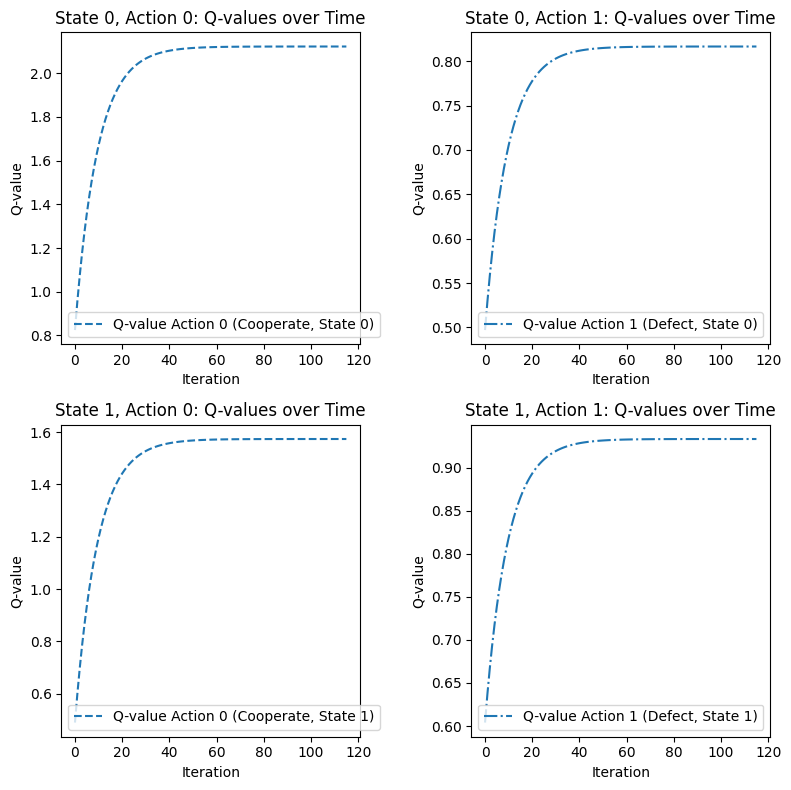

Cooperations: 458, Defections: 0


In [5]:
# Run the solver
cooperations, defections, q1_history, mean_q_values, grim_trigger_count_dict, initial_q_value = solver.run()
# Check results
print(f"Cooperations: {cooperations}, Defections: {defections}")


### Calculate Theoretical Q-Values

In [6]:
calculator = Theoretical_QValueCalculator(epsilon=epsilon_value, P=P, R=R, T=T, S=S, delta=delta_value)
Q00, Q01, Q10, Q11 = calculator.calculate_q_values(c1, c2)


### Value Iteration Check

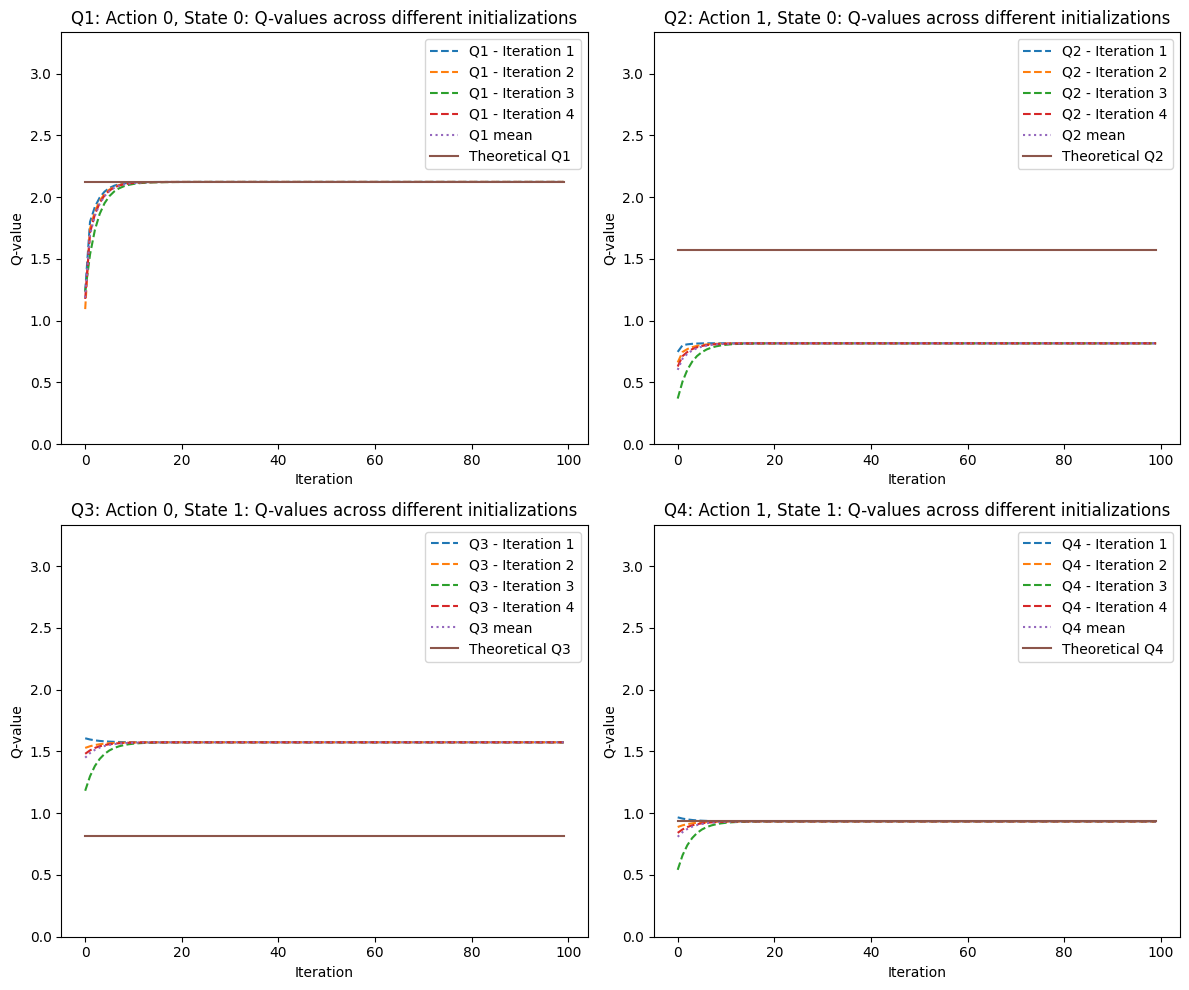

In [7]:
solver.plot_value_iteration(Q00, Q01, Q10, Q11, False)

In [8]:


def latin_hypercube_sampling(T, delta):
    
    upper_limit = T / (1 - delta)
    sampler = qmc.LatinHypercube(d=1)
    sample = sampler.random(n=4) * upper_limit
    unique_2x2_array = sample.reshape(2, 2)
    while len(np.unique(unique_2x2_array)) < 4:
        sample = sampler.random(n=1)
        unique_2x2_array = sample.reshape(2, 2)
    
    return unique_2x2_array


In [9]:
latin_hypercube_sampling(1, delta_value)

array([[3.05355988, 1.50802822],
       [0.63271334, 1.92596277]])

In [10]:
break

SyntaxError: 'break' outside loop (668683560.py, line 1)

## Detailed debug

In [17]:
pi2 = epsilon_GrimTrigger().get_action(epsilon_value=epsilon_value)
pi2

array([[0.9, 0.1],
       [0.1, 0.9]])

In [18]:
game_structure = Game_Model_Structure(2, 2, 1, 0.8, 0.2, 0)
P_CC, P_CD, P_DC, P_DD = game_structure.get_probability_matrices()
r1 = game_structure.get_reward_matrix()
r1

array([[0.8, 0. ],
       [1. , 0.2]])

In [23]:
r1_pi2 = np.dot(r1, pi2)
r1_pi2

array([[0.72, 0.08],
       [0.92, 0.28]])

In [24]:
P1_C_pi2 = np.array([P_CC[0] * pi2[0, 0] + P_CD[0] * pi2[1, 0], P_CC[1] * pi2[0, 1] + P_CD[1] * pi2[1, 1]])
P1_D_pi2 = np.array([P_DC[0] * pi2[0, 0] + P_DD[0] * pi2[1, 0],  P_DC[1] * pi2[0, 1] + P_DD[1] * pi2[1, 1]])


In [25]:
P1_C_pi2

array([[0.9, 0.1],
       [0.1, 0.9]])

In [26]:
P1_D_pi2

array([[0., 1.],
       [0., 1.]])

In [28]:
q1 = generate_unique_complete_samplings(1, delta_value)
q1

array([[2.37855808, 0.63025571],
       [0.32618891, 2.5497746 ]])

In [30]:
q1_max = np.max(q1, axis=0)
q1_max

array([2.37855808, 2.5497746 ])

In [33]:
np.dot(P1_C_pi2, q1_max)

array([2.39567973, 2.53265294])

In [34]:
np.dot(P1_D_pi2, q1_max)

array([2.5497746, 2.5497746])

In [31]:
q1_new = np.vstack((np.dot(P1_C_pi2, q1_max), np.dot(P1_D_pi2, q1_max)))
q1_new

array([[2.39567973, 2.53265294],
       [2.5497746 , 2.5497746 ]])

In [32]:
q1_new = r1_pi2 + delta_value * q1_new.copy()
q1_new

array([[2.39697581, 1.85285706],
       [2.70484222, 2.06484222]])

## Multiple Random Seed

In [ ]:
seeds = random.sample(range(1, 10000), 10)

all_cooperations = []
all_defections = []

for seed in seeds:
    random.seed(seed)
    strategy = GrimTrigger_QValues()  # Or use TitForTat()
    solver = PrisonersDilemmaSolver(strategy, e_initial=epsilon_value, 
                                    lambda_val=0.1, 
                                    alpha=0.05, 
                                    delta=0.9, 
                                    K=100, 
                                    M=10, 
                                    e_decay=0.95, 
                                    verbose=False, plotting = False)
    
    cooperations, defections, q = solver.run()
    all_cooperations.append(cooperations)
    all_defections.append(defections)

all_cooperations = np.array(all_cooperations)
all_defections = np.array(all_defections)

mean_cooperations = np.mean(all_cooperations)
mean_defections = np.mean(all_defections)

print(f"Mean cooperations: {mean_cooperations}")
print(f"Mean defections: {mean_defections}")


NameError: name 'random' is not defined

## Critical Value of delta

In [ ]:
## Should this be changed, putting how many times it learns to play gt instead or number of cooperations?
break

In [ ]:
def analyze_critical_delta(strategy, e_initial, lambda_val, alpha, delta_range, K, M, e_decay, random_uniform=True):
    """
    Analyzes the critical value of delta for which the agent begins cooperating against the Grim Trigger strategy.
    
    Parameters:
        strategy: The opponent strategy (e.g., GrimTrigger).
        e_initial: Initial exploration rate for Q-learning.
        lambda_val: Eligibility decay parameter.
        alpha: Learning rate for Q-learning.
        delta_range: Tuple specifying the range of delta (min, max, step).
        K: Number of iterations per episode.
        M: Number of episodes to train.
        e_decay: Decay rate for exploration rate.
        random_uniform: Whether to initialize Q-values randomly.
    
    Returns:
        A plot of cooperation ratio vs. delta.
    """
    deltas = np.arange(delta_range[0], delta_range[1], delta_range[2])
    cooperation_ratios = []

    for delta in deltas:
        print(f"Running for delta = {delta:.2f}...")  # Verbose output to track progress
        # Initialize the solver for the given delta
        solver = PrisonersDilemmaSolver(
            strategy=strategy,
            e_initial=e_initial,
            lambda_val=lambda_val,
            alpha=alpha,
            delta=delta,
            K=K,
            M=M,
            e_decay=e_decay,
            random_uniform=random_uniform,
            verbose=False,
            plotting=False  # Suppress plotting for individual runs
        )
        # Run the solver and collect results
        cooperations, defections, _, _, = solver.run()

        # Calculate cooperation ratio
        total_actions = cooperations + defections
        cooperation_ratio = cooperations / total_actions if total_actions > 0 else 0
        cooperation_ratios.append(cooperation_ratio)

    # Plot the cooperation ratio as a function of delta
    plt.figure(figsize=(10, 6))
    plt.plot(deltas, cooperation_ratios, marker='o', linestyle='-', label="Cooperation Ratio")
    plt.axhline(y=0.5, color='r', linestyle='--', label="50% Cooperation Threshold")
    plt.xlabel("Delta (Discount Factor)")
    plt.ylabel("Cooperation Ratio")
    plt.title("Cooperation Ratio vs. Delta in Prisoner's Dilemma")
    plt.legend()
    plt.grid()
    plt.show()

    # Return raw data for further analysis if needed
    return deltas, cooperation_ratios


Running for delta = 0.50...
Running for delta = 0.55...
Running for delta = 0.60...
Running for delta = 0.65...
Running for delta = 0.70...
Running for delta = 0.75...
Running for delta = 0.80...
Running for delta = 0.85...
Running for delta = 0.90...


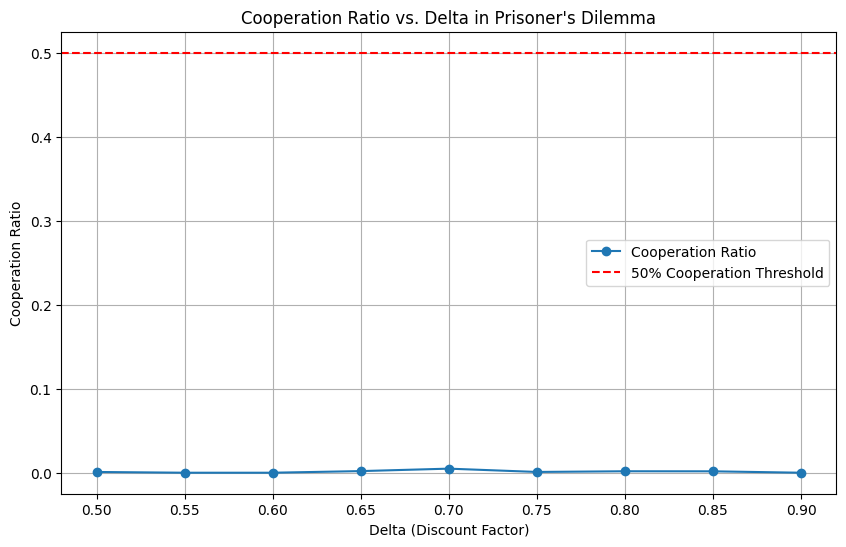

In [ ]:
# Define parameters for the experiment
strategy = GrimTrigger_QValues()
e_initial = epsilon_value
lambda_val = 0.1
alpha = 0.1
delta_range =  (0.5, 0.95, 0.05)# Analyze delta from 0.5 to 1.0 in steps of 0.01
K = 500 # Number of iterations per episode
M = 10  # Number of episodes
e_decay = 1  # Decay rate for exploration
random_uniform = False  # Initialize Q-values randomly

# Run the analysis
deltas, cooperation_ratios = analyze_critical_delta(
    strategy=strategy,
    e_initial=e_initial,
    lambda_val=lambda_val,
    alpha=alpha,
    delta_range=delta_range,
    K=K,
    M=M,
    e_decay=e_decay,
    random_uniform=random_uniform
)


In [ ]:
cooperation_ratios

[0.0008960573476702509,
 0.0,
 0.0,
 0.0019342359767891683,
 0.004849660523763337,
 0.0009191176470588235,
 0.0017452006980802793,
 0.0016736401673640166,
 0.0]